In [12]:
import os
import pandas as pd
import helpers_old as old
import helpers as new

DXF_DIR = "10991360"
files = sorted(
    os.path.join(DXF_DIR, file)
    for file in os.listdir(DXF_DIR)
    if os.path.isfile(os.path.join(DXF_DIR, file))
)

#### Arcs
Problem: Dxf looks uncompleted

Solution: implement arcs in the load_dxf_geometry() function

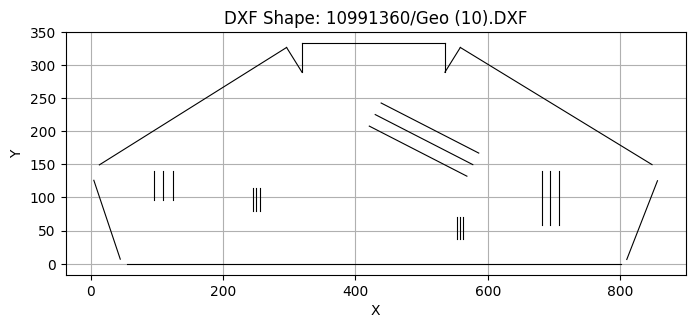

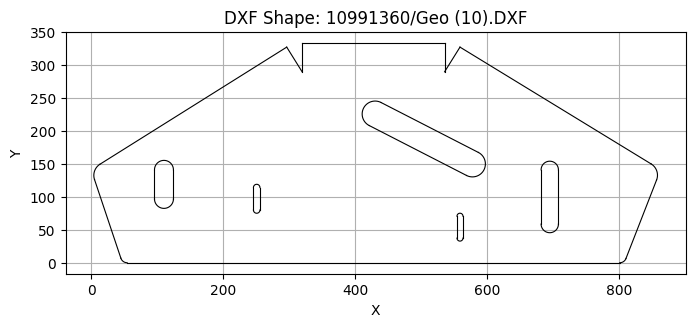

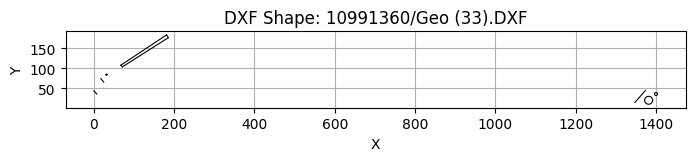

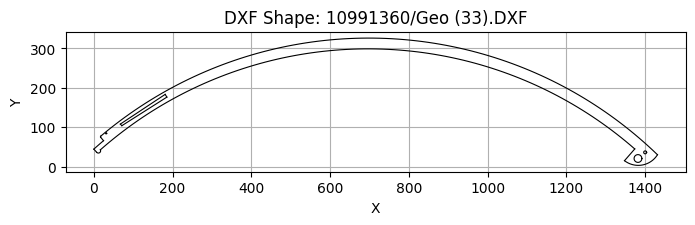

In [10]:
old.plot_dxf("10991360/Geo (10).DXF")
new.plot_dxf("10991360/Geo (10).DXF")
old.plot_dxf("10991360/Geo (33).DXF")
new.plot_dxf("10991360/Geo (33).DXF")

#### Bounding Boxes
Problem: bounding box way too big for arcs

Solution: use the bbox function of ezdxf

,bbox_area_cm2,hole_count
count,80.0,80.0
mean,4048.6,6.6
std,8836.0,18.1
min,3.8,0.0
25%,211.9,0.0
50%,718.8,2.0
75%,3082.8,6.0
max,44521.0,150.0


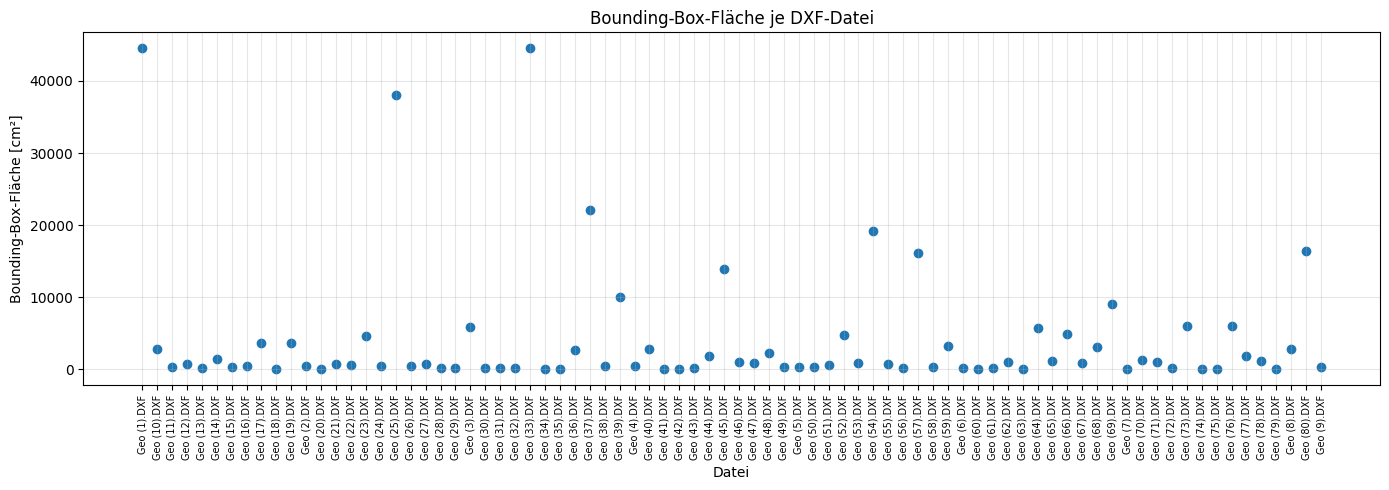

In [32]:
import matplotlib.pyplot as plt

bbs = []
for file in files:
    width, height = old.get_dxf_bounds(file)              # DXF units: mm
    bbs.append({
        "filename": os.path.basename(file),
        "bbox_area_cm2": width * height / 100,           # mm² -> cm²
        "hole_count" : old.get_number_of_holes(file)
    })

bbs_df = pd.DataFrame(bbs)
display(bbs_df.describe().round(1))

# Scatter plot: bounding box area per file
fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(bbs_df["filename"], bbs_df["bbox_area_cm2"])
ax.set_xlabel("Datei")
ax.set_ylabel("Bounding-Box-Fläche [cm²]")
ax.set_title("Bounding-Box-Fläche je DXF-Datei")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

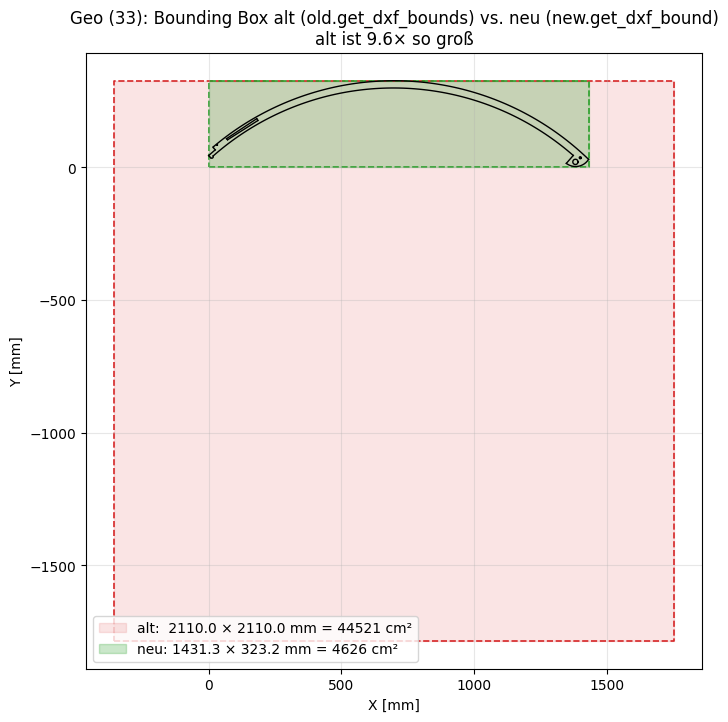

In [29]:
import ezdxf
from ezdxf import bbox


def old_bbox_corners(path):
    """Corner points of the bounding box exactly as old.get_dxf_bounds computes it
    (old.get_dxf_bounds only returns width and height)."""
    xs, ys = [], []
    for e in ezdxf.readfile(path).modelspace():
        etype = e.dxftype()
        if etype == "LINE":
            pts = [e.dxf.start, e.dxf.end]
        elif etype in ("CIRCLE", "ARC"):
            c, r = e.dxf.center, e.dxf.radius        # ARC: full circle is used!
            pts = [(c[0] - r, c[1] - r), (c[0] + r, c[1] + r)]
        elif etype == "POINT":
            pts = [e.dxf.location]
        else:
            continue
        xs += [p[0] for p in pts]
        ys += [p[1] for p in pts]
    return min(xs), min(ys), max(xs), max(ys)


def new_bbox_corners(path):
    """Corner points of the bounding box as new.get_dxf_bound computes it (ezdxf.bbox)."""
    box = bbox.extents(ezdxf.readfile(path).modelspace())
    return box.extmin.x, box.extmin.y, box.extmax.x, box.extmax.y


def draw_box(ax, corners, color, label, alpha=0.12):
    x0, y0, x1, y1 = corners
    ax.fill([x0, x1, x1, x0], [y0, y0, y1, y1], color=color, alpha=alpha, zorder=0, label=label)
    ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color=color, linestyle="--", linewidth=1.2, zorder=1)


part = "Geo (33)"
file = os.path.join(DXF_DIR, f"{part}.DXF")

box_old = old_bbox_corners(file)
box_new = new_bbox_corners(file)
width_old, height_old = old.get_dxf_bounds(file)
width_new, height_new = new.get_dxf_bound(file)
# corner reconstruction must match the helper functions
assert abs((box_old[2] - box_old[0]) - width_old) < 1e-6 and abs((box_old[3] - box_old[1]) - height_old) < 1e-6
assert abs((box_new[2] - box_new[0]) - width_new) < 1e-6 and abs((box_new[3] - box_new[1]) - height_new) < 1e-6

area_old = width_old * height_old / 100                  # mm² -> cm²
area_new = width_new * height_new / 100

# Part drawn with the new geometry loader, otherwise the arcs would be missing
polygons, lines = new.load_dxf_geometry(file)

fig, ax = plt.subplots(figsize=(10, 8))
draw_box(ax, box_old, "tab:red", f"alt:  {width_old:.1f} × {height_old:.1f} mm = {area_old:.0f} cm²")
draw_box(ax, box_new, "tab:green", f"neu: {width_new:.1f} × {height_new:.1f} mm = {area_new:.0f} cm²", alpha=0.25)
for poly in polygons:
    ax.plot(*poly.exterior.xy, color="black", linewidth=1, zorder=2)
for line in lines:
    ax.plot(*line.xy, color="black", linewidth=1, zorder=2)

ax.set_aspect("equal", "box")
ax.set_title(f"{part}: Bounding Box alt (old.get_dxf_bounds) vs. neu (new.get_dxf_bound)\n"
             f"alt ist {area_old / area_new:.1f}× so groß")
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.grid(True, alpha=0.3)
ax.legend(loc="lower left")
plt.show()

#### Holes

every circle was counted as a hole. Slotted holes, created from Lines and Arcs were not counted.

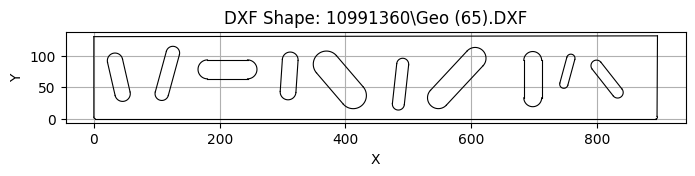

In [ ]:
new.plot_dxf(os.path.join(DXF_DIR, "Geo (65).DXF"))

#### Cutting Length

Problem: Centerlines are handled as cutlines, Arcs wrong way around

Solution: Exclude them from everything

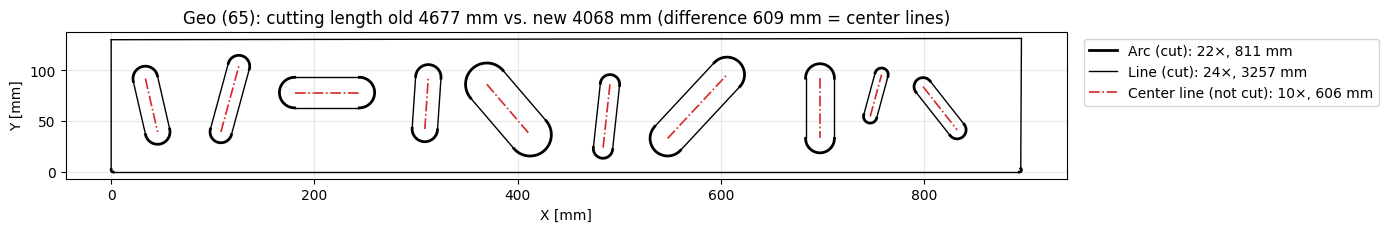

In [43]:
import numpy as np

part = "Geo (65)"
file = os.path.join(DXF_DIR, f"{part}.DXF")

# Draw the raw DXF entities: plot_dxf filters center lines, so they would not be visible
style = {
    "line":   dict(color="black", linewidth=1, zorder=2),
    "arc":    dict(color="black", linewidth=2, zorder=3),
    "circle": dict(color="black", linewidth=1, zorder=2),
    "center": dict(color="tab:red", linewidth=1.2, linestyle="-.", zorder=1),
}
labels = {"line": "Line (cut)", "arc": "Arc (cut)", "circle": "Circle (cut)", "center": "Center line (not cut)"}
count = dict.fromkeys(style, 0)
length = dict.fromkeys(style, 0.0)

fig, ax = plt.subplots(figsize=(14, 5))
for e in ezdxf.readfile(file).modelspace():
    etype = e.dxftype()
    if etype == "LINE":
        kind = "line" if e.dxf.linetype == "Continuous" else "center"
        pts = [e.dxf.start, e.dxf.end]
    elif etype == "ARC":
        kind = "arc"
        pts = list(e.flattening(sagitta=0.01))
    elif etype == "CIRCLE":
        kind = "circle"
        pts = list(e.flattening(sagitta=0.01))
    else:
        continue                                     # POINTs have no length
    x, y = [p[0] for p in pts], [p[1] for p in pts]
    ax.plot(x, y, label=labels[kind] if count[kind] == 0 else None, **style[kind])
    count[kind] += 1
    length[kind] += np.hypot(np.diff(x), np.diff(y)).sum()

len_old = old.get_cutting_length(file)
len_new = new.get_cutting_length(file)

# Legend with number and length per entity type
handles, legend_labels = ax.get_legend_handles_labels()
kinds = {v: k for k, v in labels.items()}
legend_labels = [f"{l}: {count[kinds[l]]}×, {length[kinds[l]]:.0f} mm" for l in legend_labels]
ax.legend(handles, legend_labels, loc="upper left", bbox_to_anchor=(1.01, 1))

ax.set_aspect("equal", "box")
ax.set_title(f"{part}: cutting length old {len_old:.0f} mm vs. new {len_new:.0f} mm "
             f"(difference {len_old - len_new:.0f} mm = center lines)")
ax.set_xlabel("X [mm]")
ax.set_ylabel("Y [mm]")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()